<a href="https://colab.research.google.com/github/Jyotisrj/sql-sales-data-analysis-/blob/main/Python_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**E-commerce Delivery & Logistics Performance Analysis**

Role: Python Analysis

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

Dataset: Brazilian E-Commerce (Olist)

Objectives
Analyse order and delivery performance.
Calculate average delivery time and on-time/late delivery rates.
Identify monthly order trends and order status distribution.
Analyse freight costs and state-wise delivery performance.
Export summary tables and charts for the Power BI dashboard.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Step 1 — Project setup and load datasets**

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path(
    "/content/drive/MyDrive/Ecommerce_Project/olist_cleaned_data_updated"
)

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Customers:", customers.shape)
print("Sellers:", sellers.shape)

Orders: (99441, 8)
Order items: (112650, 7)
Customers: (99441, 5)
Sellers: (3095, 4)


**Step 2 — Inspect data quality**

In [3]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Sellers": sellers
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:\n", df.isnull().sum())
    print("Columns:", df.columns.tolist())

print("\nUnique orders:", orders["order_id"].nunique())
print("Orders with item records:", order_items["order_id"].nunique())


--- Orders ---
Shape: (99441, 8)
Duplicate rows: 0
Missing values:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

--- Order Items ---
Shape: (112650, 7)
Duplicate rows: 0
Missing values:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

--- Customers ---
Shape: (99441, 5)

**Step 3 — Convert dates and prepare analysis populations**

In [4]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# All orders
total_unique_orders = orders["order_id"].nunique()

# Orders with available product-price data
orders_with_price = (
    order_items.groupby("order_id")["price"]
    .sum(min_count=1)
    .dropna()
    .index
)

orders_with_items = orders[
    orders["order_id"].isin(orders_with_price)
].copy()

orders_with_items_count = orders_with_items["order_id"].nunique()

print("All orders:", total_unique_orders)
print("Orders with available price data:", orders_with_items_count)

All orders: 99441
Orders with available price data: 98666


**Step 4 — Order status distribution**

This version uses the 99441 orders with item records.

In [7]:
# Calculate total orders
total_orders = orders["order_id"].nunique()

print("Total unique orders:", total_orders)
# Analyze order status
status_summary = (
    orders.groupby("order_status")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

status_summary["percentage"] = (
    status_summary["total_orders"] / total_orders * 100
).round(2)

status_summary = status_summary.sort_values(
    "total_orders", ascending=False
)

display(status_summary)

Total unique orders: 99441


,order_status,total_orders,percentage
3,delivered,96478,97.02
6,shipped,1107,1.11
1,canceled,625,0.63
7,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
2,created,5,0.01
0,approved,2,0.00


This version uses the 98666 orders with item records.

In [5]:
status_summary = (
    orders_with_items.groupby("order_status")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

status_summary["percentage"] = (
    status_summary["total_orders"]
    / orders_with_items_count * 100
).round(2)

status_summary = status_summary.sort_values(
    "total_orders", ascending=False
).reset_index(drop=True)

display(status_summary)

,order_status,total_orders,percentage
0,delivered,96478,97.78
1,shipped,1106,1.12
2,canceled,461,0.47
3,invoiced,312,0.32
4,processing,301,0.31
5,unavailable,6,0.01
6,approved,2,0.00


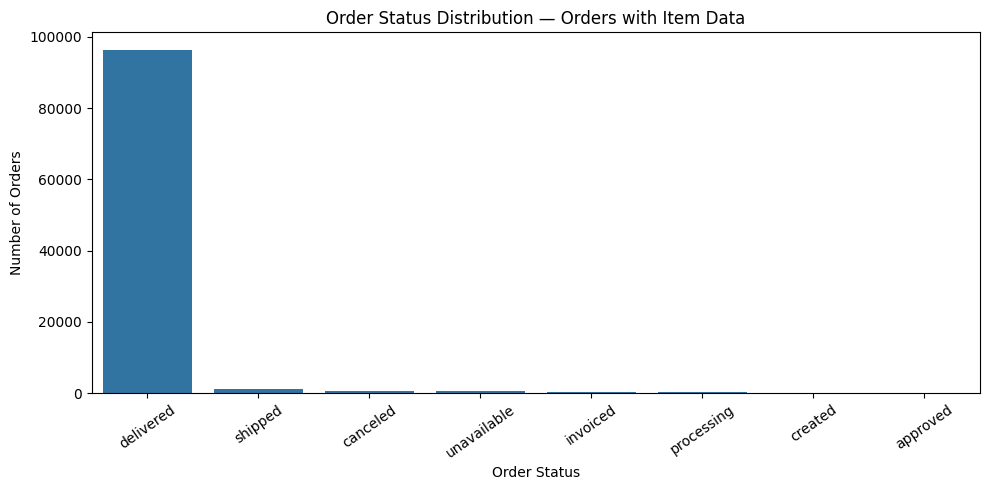

In [8]:
plt.figure(figsize=(10, 5))
sns.barplot(data=status_summary, x="order_status", y="total_orders")
plt.title("Order Status Distribution — Orders with Item Data")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig("order_status_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

**Step 5 — Cancellation rate**

In [9]:
cancelled_orders_all = orders.loc[
    orders["order_status"].eq("canceled"), "order_id"
].nunique()

cancellation_rate_all = (
    cancelled_orders_all / total_unique_orders * 100
)

cancelled_orders_with_items = orders_with_items.loc[
    orders_with_items["order_status"].eq("canceled"), "order_id"
].nunique()

cancellation_rate_with_items = (
    cancelled_orders_with_items / orders_with_items_count * 100
)

print("FULL DATASET")
print("Total orders:", total_unique_orders)
print("Canceled orders:", cancelled_orders_all)
print(f"Cancellation rate: {cancellation_rate_all:.2f}%")

print("\nORDERS WITH ITEM DATA")
print("Total orders:", orders_with_items_count)
print("Canceled orders:", cancelled_orders_with_items)
print(f"Cancellation rate: {cancellation_rate_with_items:.2f}%")

FULL DATASET
Total orders: 99441
Canceled orders: 625
Cancellation rate: 0.63%

ORDERS WITH ITEM DATA
Total orders: 98666
Canceled orders: 461
Cancellation rate: 0.47%


**Step 6 — Average delivery days**

In [10]:
delivery_orders = orders_with_items[
    orders_with_items["order_status"].eq("delivered")
    & orders_with_items["order_purchase_timestamp"].notna()
    & orders_with_items["order_delivered_customer_date"].notna()
].copy()

delivery_orders["delivery_days"] = (
    delivery_orders["order_delivered_customer_date"].dt.normalize()
    - delivery_orders["order_purchase_timestamp"].dt.normalize()
).dt.days

delivery_orders = delivery_orders[
    delivery_orders["delivery_days"] >= 0
].copy()

average_delivery_days = delivery_orders["delivery_days"].mean()

print("Orders with item data:", orders_with_items_count)
print("Valid delivered orders included:", len(delivery_orders))
print(f"Average Delivery Days: {average_delivery_days:.2f}")

Orders with item data: 98666
Valid delivered orders included: 96470
Average Delivery Days: 12.50


**Step 7 — On-time and late delivery**

An order is on time when its actual customer-delivery timestamp is on or before its estimated delivery timestamp.

In [11]:
delivery_performance = orders_with_items[
    orders_with_items["order_status"].eq("delivered")
    & orders_with_items["order_delivered_customer_date"].notna()
    & orders_with_items["order_estimated_delivery_date"].notna()
].copy()

delivery_performance["is_on_time"] = (
    delivery_performance["order_delivered_customer_date"]
    <= delivery_performance["order_estimated_delivery_date"]
)

evaluated_orders = delivery_performance["order_id"].nunique()

on_time_orders = delivery_performance.loc[
    delivery_performance["is_on_time"], "order_id"
].nunique()

late_orders = evaluated_orders - on_time_orders

on_time_rate = on_time_orders / evaluated_orders * 100
late_rate = late_orders / evaluated_orders * 100

print("Delivered orders evaluated:", evaluated_orders)
print("On-time orders:", on_time_orders)
print("Late orders:", late_orders)
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Late delivery rate: {late_rate:.2f}%")

Delivered orders evaluated: 96470
On-time orders: 88644
Late orders: 7826
On-time delivery rate: 91.89%
Late delivery rate: 8.11%


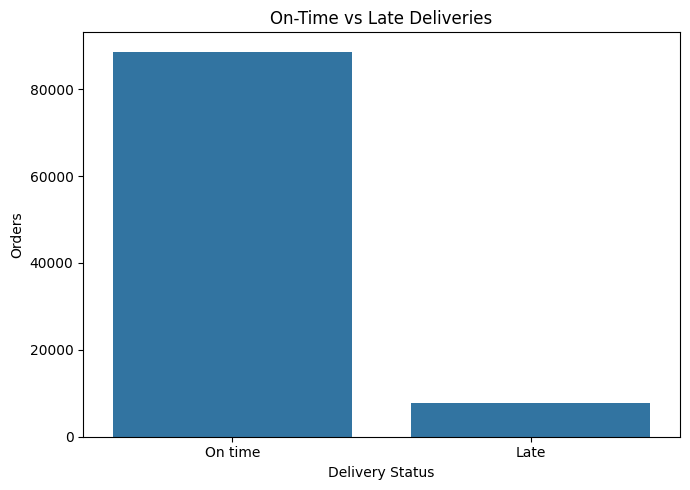

In [12]:
delivery_status_summary = pd.DataFrame({
    "Delivery Status": ["On time", "Late"],
    "Orders": [on_time_orders, late_orders]
})

plt.figure(figsize=(7, 5))
sns.barplot(
    data=delivery_status_summary,
    x="Delivery Status",
    y="Orders"
)
plt.title("On-Time vs Late Deliveries")
plt.tight_layout()
plt.savefig("on_time_vs_late_deliveries.png", dpi=300, bbox_inches="tight")
plt.show()

**Step 8 — Delivery delay and processing time**

In [13]:
# Actual delivery minus estimated delivery
delay_data = delivery_performance[
    delivery_performance["order_delivered_customer_date"]
    >= delivery_performance["order_purchase_timestamp"]
].copy()

delay_data["delay_days"] = (
    delay_data["order_delivered_customer_date"]
    - delay_data["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

average_delay_days = delay_data["delay_days"].mean()

late_only = delay_data[delay_data["delay_days"] > 0]
average_late_delay = late_only["delay_days"].mean()

print(f"Average actual minus estimated delivery: {average_delay_days:.2f} days")
print(f"Average delay among late orders: {average_late_delay:.2f} days")

Average actual minus estimated delivery: -11.18 days
Average delay among late orders: 9.55 days


In [14]:
# Purchase to carrier handover
carrier_data = orders.dropna(
    subset=["order_purchase_timestamp", "order_delivered_carrier_date"]
).copy()

carrier_data["hours"] = (
    carrier_data["order_delivered_carrier_date"]
    - carrier_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

carrier_data = carrier_data[carrier_data["hours"] >= 0]
average_purchase_to_carrier_hours = carrier_data["hours"].mean()

# Purchase to order approval
approval_data = orders.dropna(
    subset=["order_purchase_timestamp", "order_approved_at"]
).copy()

approval_data["hours"] = (
    approval_data["order_approved_at"]
    - approval_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

approval_data = approval_data[approval_data["hours"] >= 0]
average_purchase_to_approval_hours = approval_data["hours"].mean()

print(f"Purchase-to-carrier: {average_purchase_to_carrier_hours:.2f} hours")
print(f"Purchase-to-approval: {average_purchase_to_approval_hours:.2f} hours")

Purchase-to-carrier: 77.79 hours
Purchase-to-approval: 10.42 hours


**Step 9 — Monthly order trends**

Count all orders by the month they were purchased.

,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


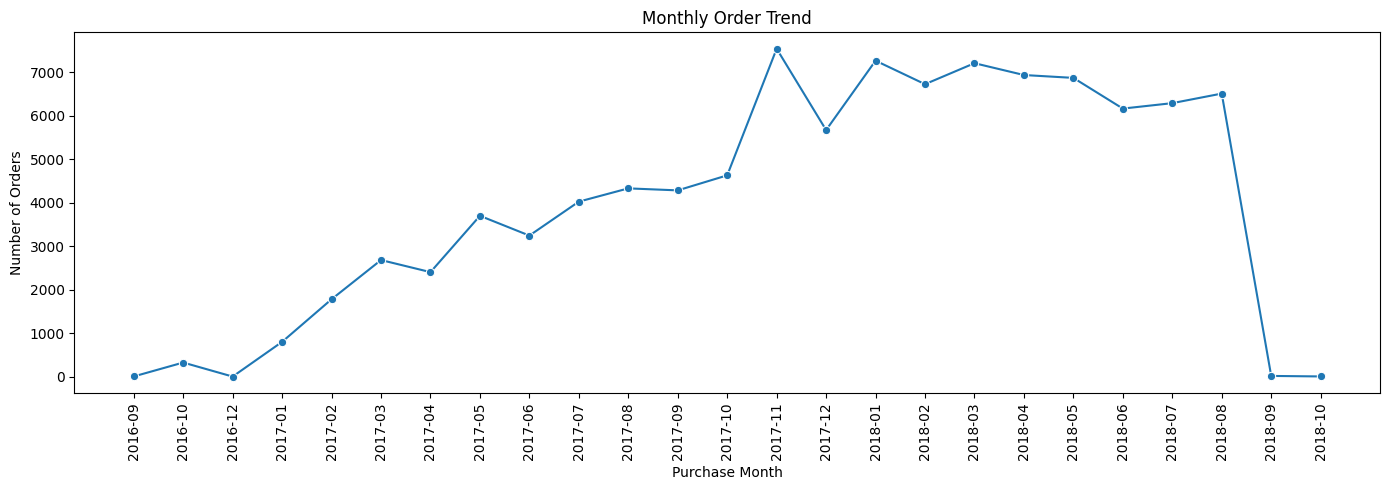

In [15]:
monthly_orders = orders[
    orders["order_purchase_timestamp"].notna()
].copy()

monthly_orders["order_month"] = (
    monthly_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_orders = (
    monthly_orders.groupby("order_month")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

display(monthly_orders.head(10))

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=monthly_orders,
    x="order_month",
    y="total_orders",
    marker="o"
)
plt.title("Monthly Order Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("monthly_order_trends.png", dpi=300, bbox_inches="tight")
plt.show()

**Step 10 — Freight cost and Average Order Value**

These metrics use the 98,666 orders with item data.

In [16]:
order_totals = order_items.groupby("order_id").agg(
    product_value=("price", lambda x: x.sum(min_count=1)),
    freight_cost=("freight_value", lambda x: x.sum(min_count=1))
)

valid_orders = order_totals.dropna(
    subset=["product_value", "freight_cost"]
).copy()

valid_orders["total_order_value"] = (
    valid_orders["product_value"] + valid_orders["freight_cost"]
)

freight_orders_count = len(valid_orders)
total_freight_cost = valid_orders["freight_cost"].sum()
average_freight_per_order = valid_orders["freight_cost"].mean()
median_freight_per_order = valid_orders["freight_cost"].median()

total_product_value = valid_orders["product_value"].sum()
average_order_value = valid_orders["product_value"].mean()

total_value_including_freight = valid_orders["total_order_value"].sum()
average_order_value_including_freight = (
    valid_orders["total_order_value"].mean()
)

print("Orders included:", freight_orders_count)
print(f"Total Freight Cost: R$ {total_freight_cost:,.2f}")
print(f"Average Freight per Order: R$ {average_freight_per_order:.2f}")
print(f"Median Freight per Order: R$ {median_freight_per_order:.2f}")
print(f"Total Product Value: R$ {total_product_value:,.2f}")
print(f"Product-only AOV: R$ {average_order_value:.2f}")
print(f"Total Value Including Freight: R$ {total_value_including_freight:,.2f}")
print(f"AOV Including Freight: R$ {average_order_value_including_freight:.2f}")

Orders included: 98666
Total Freight Cost: R$ 2,251,909.54
Average Freight per Order: R$ 22.82
Median Freight per Order: R$ 17.17
Total Product Value: R$ 13,591,643.70
Product-only AOV: R$ 137.75
Total Value Including Freight: R$ 15,843,553.24
AOV Including Freight: R$ 160.58


**Step 11 — State-wise performance**

First, create the customer-state dataset:

In [17]:
regional_orders = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

**1: Cancellation rate by customer state**

Cancellation rate is calculated as the number of canceled orders divided by all orders for each customer state.

In [18]:
# Group all orders by customer state
regional_cancellation = (
    regional_orders
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "order_status",
            lambda x: (x == "canceled").sum()
        )
    )
    .reset_index()
)

# Calculate cancellation percentage
regional_cancellation["cancellation_rate_pct"] = (
    regional_cancellation["cancelled_orders"]
    / regional_cancellation["total_orders"]
    * 100
)

# Sort from highest to lowest cancellation rate
regional_cancellation = regional_cancellation.sort_values(
    "cancellation_rate_pct",
    ascending=False
).reset_index(drop=True)

display(regional_cancellation.round(2))

,customer_state,total_orders,cancelled_orders,cancellation_rate_pct
0,RR,46,1,2.17
1,RO,253,3,1.19
2,PI,495,4,0.81
3,SP,41746,327,0.78
4,RJ,12852,86,0.67
5,GO,2020,13,0.64
6,MG,11635,64,0.55
7,MA,747,4,0.54
8,CE,1336,7,0.52
9,SC,3637,19,0.52


**2: Average delivery days by customer state**
In this calculation includes only orders that:
- Have delivered status.
- Have both purchase and actual delivery timestamps.
- Have a nonnegative delivery duration.
This version calculates calendar days, matching the whole-day calculation used in Power BI dashboard.

In [19]:
# Keep delivered orders with the required timestamps
delivery_orders = regional_orders[
    (regional_orders["order_status"] == "delivered")
    & regional_orders["order_purchase_timestamp"].notna()
    & regional_orders["order_delivered_customer_date"].notna()
].copy()

# Calculate whole calendar days between purchase and delivery
delivery_orders["delivery_days"] = (
    delivery_orders["order_delivered_customer_date"].dt.normalize()
    - delivery_orders["order_purchase_timestamp"].dt.normalize()
).dt.days

# Exclude invalid negative durations
delivery_orders = delivery_orders[
    delivery_orders["delivery_days"] >= 0
].copy()

# Calculate average delivery days for each customer state
regional_delivery_summary = (
    delivery_orders
    .groupby("customer_state")
    .agg(
        delivered_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
    .sort_values("average_delivery_days", ascending=False)
    .reset_index(drop=True)
)

display(regional_delivery_summary.round(2))

,customer_state,delivered_orders,average_delivery_days
0,RR,41,29.34
1,AP,67,27.18
2,AM,145,26.36
3,AL,397,24.50
4,PA,946,23.73
5,MA,717,21.51
6,SE,335,21.46
7,CE,1279,21.20
8,AC,80,21.00
9,PB,517,20.39


**3: On-time delivery rate by customer state**

An order is considered on time when its actual delivery timestamp is earlier than or equal to its estimated delivery timestamp.

In [20]:
# Keep delivered orders with actual and estimated delivery timestamps
on_time_orders_data = regional_orders[
    (regional_orders["order_status"] == "delivered")
    & regional_orders["order_delivered_customer_date"].notna()
    & regional_orders["order_estimated_delivery_date"].notna()
].copy()

# Compare actual delivery against estimated delivery
on_time_orders_data["delivery_performance"] = np.where(
    on_time_orders_data["order_delivered_customer_date"]
    <= on_time_orders_data["order_estimated_delivery_date"],
    "On Time",
    "Late"
)

# Summarize delivery performance by customer state
regional_on_time_summary = (
    on_time_orders_data
    .groupby("customer_state")
    .agg(
        evaluated_orders=("order_id", "nunique"),
        on_time_orders=(
            "delivery_performance",
            lambda x: (x == "On Time").sum()
        ),
        late_orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

# Calculate on-time and late delivery percentages
regional_on_time_summary["on_time_rate_pct"] = (
    regional_on_time_summary["on_time_orders"]
    / regional_on_time_summary["evaluated_orders"]
    * 100
)

regional_on_time_summary["late_rate_pct"] = (
    regional_on_time_summary["late_orders"]
    / regional_on_time_summary["evaluated_orders"]
    * 100
)

# Sort from highest to lowest on-time rate
regional_on_time_summary = regional_on_time_summary.sort_values(
    "on_time_rate_pct",
    ascending=False
).reset_index(drop=True)

display(regional_on_time_summary.round(2))

,customer_state,evaluated_orders,on_time_orders,late_orders,on_time_rate_pct,late_rate_pct
0,RO,243,236,7,97.12,2.88
1,AC,80,77,3,96.25,3.75
2,AM,145,139,6,95.86,4.14
3,AP,67,64,3,95.52,4.48
4,PR,4923,4677,246,95.00,5.00
5,MG,11354,10717,637,94.39,5.61
6,SP,40494,38107,2387,94.11,5.89
7,MT,886,826,60,93.23,6.77
8,DF,2080,1933,147,92.93,7.07
9,RS,5344,4962,382,92.85,7.15


**4: Create charts for each regional summary**

These charts show the 10 states with the highest cancellation rates, longest average delivery durations, and highest on-time delivery rates.

**Chart 1 — Top 10 customer states by cancellation rate**

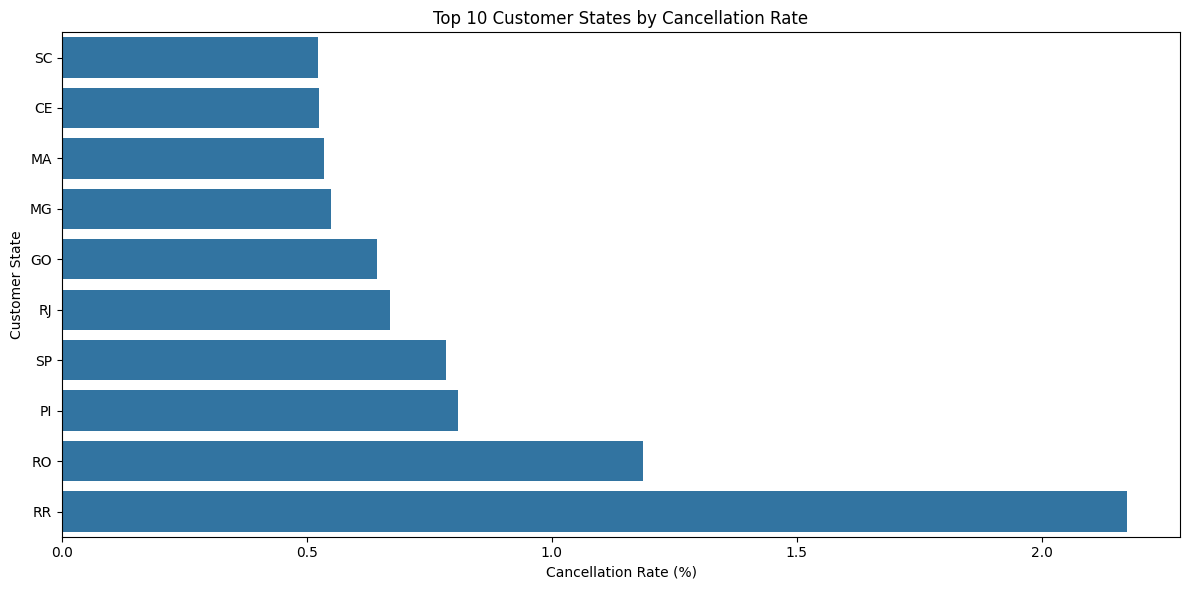

In [21]:
top_cancellation_states = (
    regional_cancellation
    .nlargest(10, "cancellation_rate_pct")
    .sort_values("cancellation_rate_pct")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_cancellation_states,
    x="cancellation_rate_pct",
    y="customer_state"
)

plt.title("Top 10 Customer States by Cancellation Rate")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Customer State")
plt.tight_layout()
plt.savefig("regional_cancellation_rate.png", dpi=300, bbox_inches="tight")
plt.show()

**Chart 2 — Top 10 customer states by average delivery days**

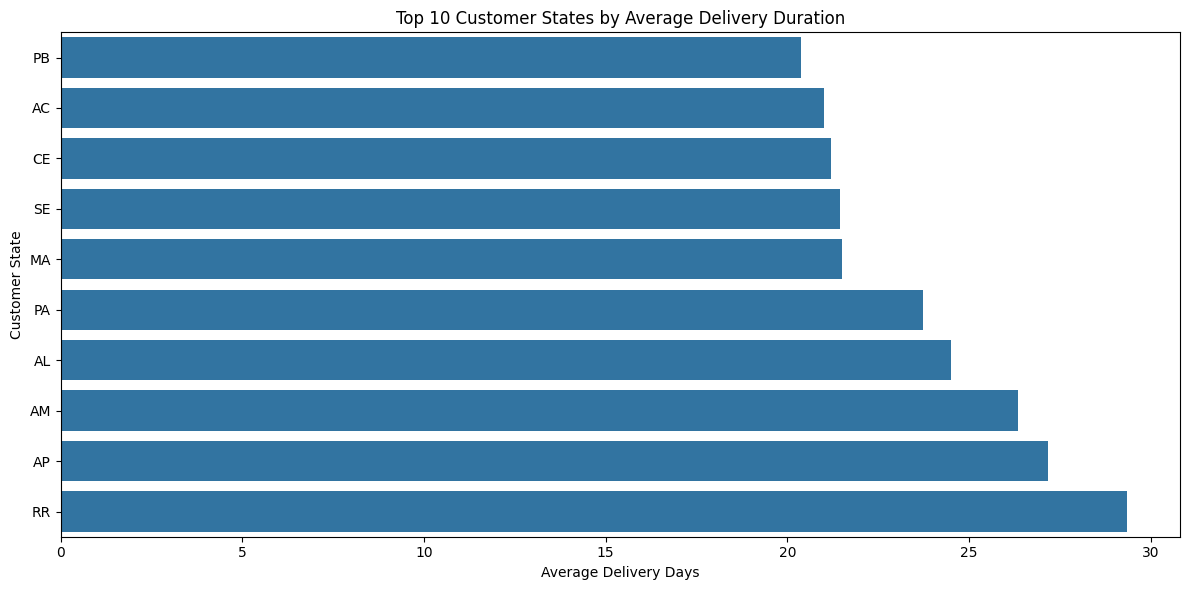

In [22]:
top_delivery_states = (
    regional_delivery_summary
    .nlargest(10, "average_delivery_days")
    .sort_values("average_delivery_days")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_delivery_states,
    x="average_delivery_days",
    y="customer_state"
)

plt.title("Top 10 Customer States by Average Delivery Duration")
plt.xlabel("Average Delivery Days")
plt.ylabel("Customer State")
plt.tight_layout()
plt.savefig("regional_average_delivery_days.png", dpi=300, bbox_inches="tight")
plt.show()

**Chart 3 — Top 10 customer states by on-time delivery rate**

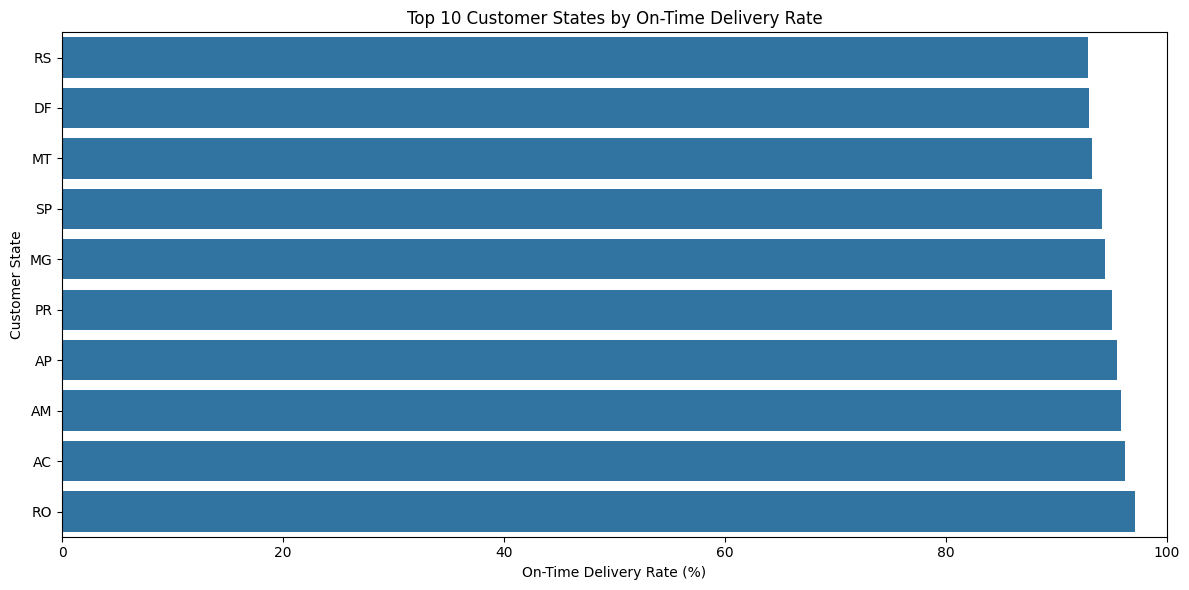

In [23]:
top_on_time_states = (
    regional_on_time_summary
    .nlargest(10, "on_time_rate_pct")
    .sort_values("on_time_rate_pct")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_on_time_states,
    x="on_time_rate_pct",
    y="customer_state"
)

plt.title("Top 10 Customer States by On-Time Delivery Rate")
plt.xlabel("On-Time Delivery Rate (%)")
plt.ylabel("Customer State")
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig("regional_on_time_delivery_rate.png", dpi=300, bbox_inches="tight")
plt.show()

**Optional Chart 4 — On-time vs. late deliveries by customer state**

This lets you compare both percentages for the states with the most evaluated deliveries.

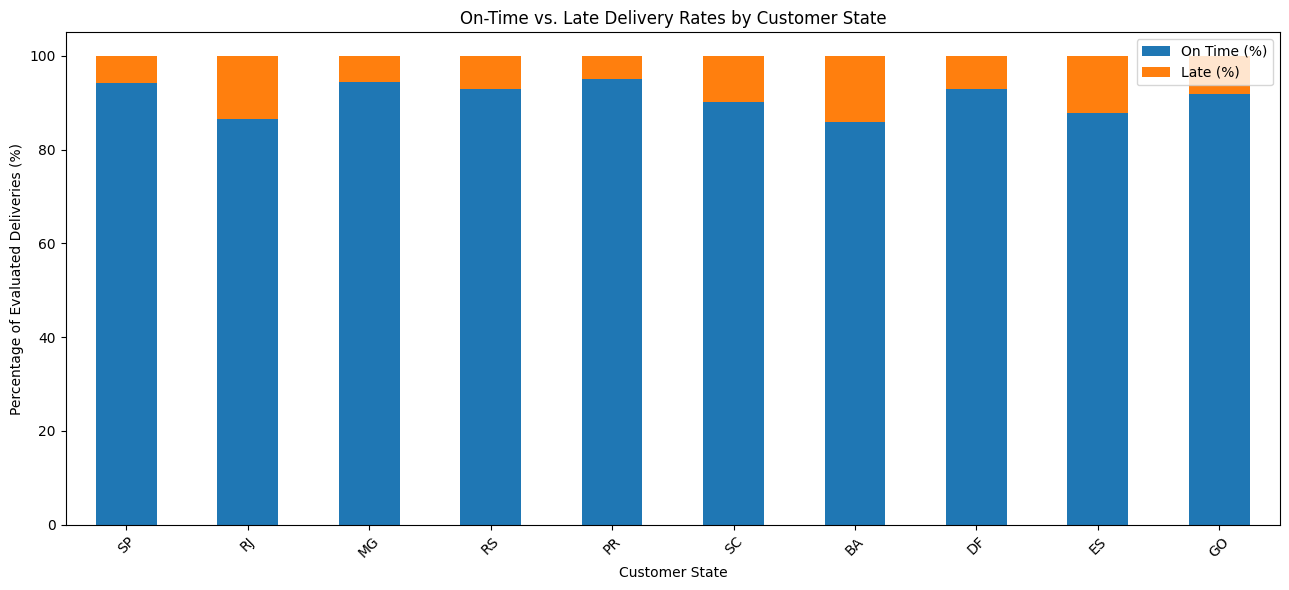

In [24]:
top_volume_states = (
    regional_on_time_summary
    .nlargest(10, "evaluated_orders")
    .sort_values("evaluated_orders", ascending=False)
)

chart_data = top_volume_states.set_index("customer_state")[
    ["on_time_rate_pct", "late_rate_pct"]
]

chart_data.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("On-Time vs. Late Delivery Rates by Customer State")
plt.xlabel("Customer State")
plt.ylabel("Percentage of Evaluated Deliveries (%)")
plt.xticks(rotation=45)
plt.legend(["On Time (%)", "Late (%)"])
plt.tight_layout()
plt.savefig("regional_on_time_vs_late.png", dpi=300, bbox_inches="tight")
plt.show()

**5: Export the regional summary tables**

In [25]:
# Create an output folder
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export regional summaries
regional_cancellation.to_csv(
    output_dir / "regional_cancellation_summary.csv",
    index=False
)

regional_delivery_summary.to_csv(
    output_dir / "regional_delivery_summary.csv",
    index=False
)

regional_on_time_summary.to_csv(
    output_dir / "regional_on_time_summary.csv",
    index=False
)

print("Regional summary tables exported successfully.")

Regional summary tables exported successfully.


**Step 12 — Final KPI summary and export**

In [26]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total unique orders (full dataset)",
        "Orders with item data",
        "Canceled orders (full dataset)",
        "Cancellation rate (full dataset, %)",
        "Canceled orders (with item data)",
        "Cancellation rate (with item data, %)",
        "Average delivery duration (whole calendar days)",
        "Eligible delivered orders",
        "On-time orders",
        "Late orders",
        "On-time delivery rate (%)",
        "Late delivery rate (%)",
        "Average actual minus estimated delivery (days)",
        "Average delay among late orders (days)",
        "Average purchase-to-carrier time (hours)",
        "Average purchase-to-approval time (hours)",
        "Total freight cost (BRL)",
        "Average freight per order (BRL)",
        "Median freight per order (BRL)",
        "Product-only AOV (BRL)",
        "AOV including freight (BRL)"
    ],
    "Value": [
        total_unique_orders,
        orders_with_items_count,
        cancelled_orders_all,
        round(cancellation_rate_all, 2),
        cancelled_orders_with_items,
        round(cancellation_rate_with_items, 2),
        round(average_delivery_days, 2),
        evaluated_orders,
        on_time_orders,
        late_orders,
        round(on_time_rate, 2),
        round(late_rate, 2),
        round(average_delay_days, 2),
        round(average_late_delay, 2),
        round(average_purchase_to_carrier_hours, 2),
        round(average_purchase_to_approval_hours, 2),
        round(total_freight_cost, 2),
        round(average_freight_per_order, 2),
        round(median_freight_per_order, 2),
        round(average_order_value, 2),
        round(average_order_value_including_freight, 2)
    ]
})

display(kpi_summary)

,KPI,Value
0,Total unique orders (full dataset),99441.00
1,Orders with item data,98666.00
2,Canceled orders (full dataset),625.00
3,"Cancellation rate (full dataset, %)",0.63
4,Canceled orders (with item data),461.00
5,"Cancellation rate (with item data, %)",0.47
6,Average delivery duration (whole calendar days),12.50
7,Eligible delivered orders,96470.00
8,On-time orders,88644.00
9,Late orders,7826.00


In [29]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

kpi_summary.to_csv(OUTPUT_DIR / "kpi_summary.csv", index=False)
status_summary.to_csv(OUTPUT_DIR / "order_status_summary.csv", index=False)
monthly_orders.to_csv(OUTPUT_DIR / "monthly_order_trends.csv", index=False)
regional_cancellation.to_csv(OUTPUT_DIR / "regional_cancellation_summary.csv", index=False)
regional_delivery_summary.to_csv(OUTPUT_DIR / "regional_delivery_summary.csv", index=False)
regional_on_time_summary.to_csv(OUTPUT_DIR / "regional_on_time_summary.csv", index=False)

print("Summary tables exported to:", OUTPUT_DIR.resolve())

Summary tables exported to: /content/outputs


# Final Conclusion — E-commerce Delivery & Logistics Performance Analysis

The Brazilian E-Commerce (Olist) dataset was analyzed using Python, Pandas, NumPy, Matplotlib, and Seaborn to evaluate order status, delivery performance, processing time, freight costs, and regional performance by customer state.

## Key Findings

1. **Order Analysis:** The dataset contains 99,441 unique orders, while 98,666 orders have corresponding product-price records. No duplicate rows were identified in the four datasets examined. Missing values were found in several order-delivery timestamps, so calculations requiring those timestamps used only eligible records.

2. **Order Cancellation:** Across the full dataset, 625 orders were canceled, giving a cancellation rate of 0.63%. Among orders with item data, 461 were canceled, corresponding to a cancellation rate of 0.47%. These percentages differ because they use different order populations.

3. **Delivery Performance:** The average delivery duration was 12.50 calendar days for valid delivered orders with item data. Out of 96,470 eligible delivered orders, 88,644 were delivered on time and 7,826 were delivered late. The on-time delivery rate was 91.89%, while the late delivery rate was 8.11%.

4. **Delivery Delay:** The average difference between actual and estimated delivery time was −11.18 days, meaning orders were delivered earlier than their estimated dates on average. However, among orders delivered after their estimated dates, the average delay was 9.55 days.

5. **Order Processing Time:** The average time from purchase to carrier handover was 77.79 hours, while the average time from purchase to approval was 10.42 hours. These measures help assess different stages of the order fulfillment process.

6. **Freight Costs and Order Value:** Across 98,666 orders with item data, the total freight cost was R$2,251,909.54. Average freight cost per order was R$22.82, and the median was R$17.17. Total product value was R$13,591,643.70. The average product-only order value was R$137.75, increasing to R$160.58 when freight was included.

7. **Monthly and Regional Analysis:** Monthly order trends and order-status distribution were visualized. Regional summaries and charts were also created to compare cancellation rates, average delivery duration, and on-time delivery rates across customer states. These comparisons can help identify regions that may require further investigation.

## Overall Conclusion

The analysis shows that most eligible delivered orders arrived on time, with an on-time delivery rate of 91.89%. Nevertheless, the 8.11% late-delivery rate highlights an opportunity to investigate delivery delays and improve fulfillment performance. Freight costs also represent a measurable part of the total order value and should be considered when evaluating logistics efficiency.

The regional analysis provides additional insight into differences between customer states. The findings can support business decisions related to delivery planning, order fulfillment, freight-cost monitoring, and customer satisfaction.

Finally, the summary tables and charts can be used in a Power BI dashboard to present the key performance indicators in an interactive and business-friendly format.

**Scope note:** Regional results describe customer-state performance, not carrier performance, because carrier identifiers are not available in the analyzed datasets. The analysis is descriptive and identifies patterns; it does not by itself establish the causes of cancellations or delivery delays.